# krsim tutorial

This tutorial guides you through the different parts of the simulator, stage by stage, and shows what each one produces as tables, plots and interactive maps. For each stage it says what the command needs and what it writes.

It uses a deliberately small, unrealistic run (3 hosts, 10 generations) so you can clearly see each host, each generation and how parasites are transmitted between them. Change the parameters in Stage 1 to explore. Open it with the `krsim` environment active (see [Installation](https://mrc-ide.github.io/KR_simulator/installation.html)).

Every command below is a normal terminal command — the `!` just runs it from inside the notebook, so you can copy them into a terminal as they are.

All outputs are written to `output/` next to this notebook, and every file name ends in the random seed (`123` here). Each command prints the files it wrote; the full details of every run (exact command, parameters, row counts) go to `output/KR_sim_123.log`.

In [1]:
import io
import ast
import pandas as pd
import matplotlib.pyplot as plt
import tskit

OUT = "output"
SEED = 123

## Stage 1 — simulate the transmission genealogy

The main part of the tool. It models how parasites move between human hosts through mosquitoes, generation by generation, and records the full ancestry of every parasite genome.

**Needs:** the number of human hosts (`--Nh`) and generations (`--T`), the number of parasites passed on per bite (`--K`), the superinfection probability (`--chi`), the number of oocysts per mosquito (`--C`), and a random seed. Here: 3 hosts, 10 generations, 2 parasites per bite, a superinfection probability of 0.18 and 1 oocyst per mosquito.

**Outputs:**

- `ts_123.trees` — the tree sequence: the genealogy of the current strains along the genome. Every later stage starts from this file.
- `sim_ind_node_map_123.csv` — which parasite strains each host carries.

**Optional outputs.** These are not needed by the later stages, but are useful for other analyses downstream or for understanding the run:

- `--save_lineage` writes `lineage_123.csv` and `node_id_map_123.csv`: the true generation-by-generation pedigree. The two interactive maps are drawn from these.
- `--save_pairs` writes `node_pairs_123.csv`: pairs of strains from the same meiosis.

Each file is looked at below.

In [2]:
!krsim simulate --Nh 3 --T 10 --K 2 --chi 0.18 --C 1 --random_seed 123 --output_dir output --save_lineage --save_pairs

  wrote  output/ts_123.trees
  wrote  output/sim_ind_node_map_123.csv
  wrote  output/lineage_123.csv
  wrote  output/node_id_map_123.csv
  wrote  output/node_pairs_123.csv
  done in 0.1 s



**`sim_ind_node_map_123.csv`** — which parasite strains (tree-sequence nodes) each host carries. `time` is generations before the present; `0` is the current generation.

In [3]:
hosts = pd.read_csv(f"{OUT}/sim_ind_node_map_{SEED}.csv")
current = hosts[hosts["time"] == 0]
print(f"{current['ind_id'].nunique()} current hosts carrying {len(current)} strains")
current.groupby("ind_id")["node_id"].apply(list).rename("strains").to_frame()

3 current hosts carrying 8 strains


,strains
ind_id,
8,"[0, 1, 2, 3]"
9,"[4, 5]"
10,"[6, 7]"


**`node_pairs_123.csv`** (optional, `--save_pairs`) — pairs of strains produced by the same meiosis in a mosquito. Comparing their genotypes in the strain VCF shows where recombination happened.

In [4]:
pd.read_csv(f"{OUT}/node_pairs_{SEED}.csv")

,sim_id,node_id,paired_node_id
0,123,2,3
1,123,4,5
2,123,15,16


**`lineage_123.csv`** (optional, `--save_lineage`) — the true generation-by-generation pedigree. The tree sequence is simplified, so it can skip generations; this table keeps every parent–child link. Each row is one stretch of genome (`left` to `right`) that a child inherited from a parent. `node_id_map_123.csv`, written alongside it, links these pedigree strain IDs to the IDs in the tree sequence.

In [5]:
lineage = pd.read_csv(f"{OUT}/lineage_{SEED}.csv")
links = lineage[["child_node_ID", "parent_node_ID"]].drop_duplicates()
print(f"{len(links)} parent–child links across {lineage['gen'].nunique()} generations, in {len(lineage)} genome segments")
lineage.head()

120 parent–child links across 10 generations, in 1869 genome segments


,sim_id,gen,child_node_ID,child_ind_ID,recomb_ID,parent_node_ID,parent_ind_ID,left,right
0,123,0.0,76,30,139,72,28,0.000000e+00,1.124378e+06
1,123,0.0,76,30,139,72,28,1.627369e+06,2.716924e+06
2,123,0.0,76,30,139,72,28,5.153904e+06,6.666031e+06
3,123,0.0,76,30,139,72,28,8.099059e+06,8.192024e+06
4,123,0.0,76,30,139,72,28,9.592986e+06,1.123700e+07


### Visualize the pedigree

The pairwise map only needs Stage 1's `--save_lineage` files. It writes a self-contained HTML page — open it in any web browser. (The transmission map also shows mutations, so it comes after Stage 2.)

In [6]:
!krsim pairwise-strain-pedigree-map --lineage_csv output/lineage_123.csv --node_id_map_csv output/node_id_map_123.csv --random_seed 123 --output_dir output


  wrote  output/pairwise_strain_pedigree_map_123.html
  done in 0.0 s



- `output/pairwise_strain_pedigree_map_123.html` — pick two current strains and trace them back to their shared pedigree ancestors.

Open it from the `output/` folder in any web browser. You can also explore the version from this run (seed 123) on the [website](https://mrc-ide.github.io/KR_simulator/quickstart.html#visualise-transmission).

## Stage 2 — add mutations

Mutations are superimposed on the genealogy: they are dropped along its branches at a set rate (`--mutation_rate`, default `1e-6` per base pair), so strains that share ancestry also share mutations.

**Needs:** `ts_123.trees`.

**Outputs:** `ts_mut_123.trees` — the tree sequence with mutations. Every later stage uses this file.

In [7]:
!krsim mutate --ts output/ts_123.trees --random_seed 123 --output_dir output

  wrote  output/ts_mut_123.trees
  done in 0.0 s



In [8]:
ts = tskit.load(f"{OUT}/ts_mut_{SEED}.trees")
print(f"{ts.num_samples} sampled strains, {ts.num_trees} trees, {ts.num_mutations} mutations")

8 sampled strains, 193 trees, 727 mutations


### Transmission map with mutations

Now that there are mutations, draw the transmission map: every strain and link in the pedigree, with each mutation as a × on the link and at the time it happened. Pick a chromosome and a tree to see the genealogy of one stretch of genome and its mutations.

In [9]:
!krsim strain-transmission-map --lineage_csv output/lineage_123.csv --node_id_map_csv output/node_id_map_123.csv --ts output/ts_mut_123.trees --random_seed 123 --output_dir output

  wrote  output/strain_transmission_map_123.html
  done in 0.1 s



- `output/strain_transmission_map_123.html` — open it in any web browser. You can also explore the version from this run (seed 123) on the [website](https://mrc-ide.github.io/KR_simulator/quickstart.html#visualise-transmission).

## Stage 3 — coalescence and mutation times

The coalescence times and mutation times can be read straight from the mutated tree sequence, so krsim writes them out as two separate files.

**Needs:** `ts_mut_123.trees`.

**Outputs:** `coal_T_123.csv` (coalescence times) and `mut_T_123.csv` (mutation times), shown below.

In [10]:
!krsim coal-mut --ts output/ts_mut_123.trees --random_seed 123 --output_dir output

  wrote  output/coal_T_123.csv
  wrote  output/mut_T_123.csv
  done in 0.0 s



**`coal_T_123.csv`** — for every pair of strains and every stretch of genome, when their ancestry last met (`coal_time`, in generations). Positions are relative to each chromosome.

In [11]:
coal = pd.read_csv(f"{OUT}/coal_T_{SEED}.csv")
coal.head()

,sample_1,sample_2,ancestor,chromosome,left,right,coal_time
0,0,1,10,1,0.0,74975.40906,1.0
1,0,4,14,1,0.0,74975.40906,2.0
2,0,5,14,1,0.0,74975.40906,2.0
3,0,6,14,1,0.0,74975.40906,2.0
4,0,7,14,1,0.0,74975.40906,2.0


**`mut_T_123.csv`** — every mutation: the node it sits on, its chromosome and position, and its age.

In [12]:
mut = pd.read_csv(f"{OUT}/mut_T_{SEED}.csv")
print(f"{len(mut)} mutations")
mut.head()

727 mutations


,node_id,chromosome,position,time
0,14,1,24145.0,6.115047
1,14,1,73960.0,4.697500
2,17,1,110207.0,7.082183
3,2,1,175031.0,0.655526
4,6,1,188126.0,0.428471


## Stage 4 — strain VCF

Using the mutations, krsim writes VCF files — the standard format for genetic variation data. They can be used for downstream analysis with other toolkits, or to benchmark methods against the known truth. The strain VCF holds the true genotype of every strain, as if each were sequenced on its own.

**Needs:** `ts_mut_123.trees`.

**Outputs:** `output_123_strain.vcf` — one haploid column per strain: `0` = reference allele, `1` = alternative allele.

In [13]:
!krsim vcf-strain --ts output/ts_mut_123.trees --random_seed 123 --output_dir output

  wrote  output/output_123_strain.vcf
  done in 0.0 s



In [14]:
def read_vcf(path):
    with open(path) as f:
        lines = [line for line in f if not line.startswith("##")]
    return pd.read_csv(io.StringIO("".join(lines)), sep="\t").rename(columns={"#CHROM": "CHROM"})

strain_vcf = read_vcf(f"{OUT}/output_{SEED}_strain.vcf")
print(f"{len(strain_vcf)} variant sites, {len(strain_vcf.columns) - 9} strains")
strain_vcf.head()

727 variant sites, 8 strains


,CHROM,POS,ID,REF,ALT,QUAL,FILTER,INFO,FORMAT,0,1,2,3,4,5,6,7
0,1,24145,0,A,G,.,PASS,.,GT,1,1,0,0,1,1,1,1
1,1,73960,1,C,G,.,PASS,.,GT,1,1,0,0,1,1,1,1
2,1,110207,2,C,A,.,PASS,.,GT,1,1,0,0,1,1,1,1
3,1,175031,3,T,C,.,PASS,.,GT,0,0,1,0,0,0,0,0
4,1,188126,4,A,C,.,PASS,.,GT,0,0,0,0,0,0,1,0


Each column below is one variant site, in file order (chromosome 1 first). The spacing is by site, not by genomic position; the x-axis marks where each chromosome starts.

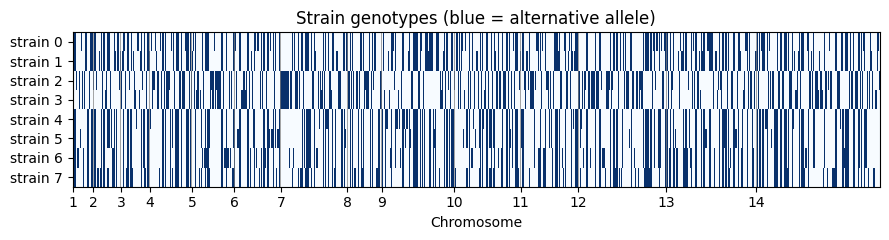

In [15]:
strains = strain_vcf.columns[9:]
chr_start = strain_vcf.reset_index().groupby("CHROM")["index"].min()

fig, ax = plt.subplots(figsize=(9, 2.5))
ax.imshow(strain_vcf[strains].astype(int).T, aspect="auto", cmap="Blues", interpolation="none")
for x in chr_start.values[1:]:
    ax.axvline(x - 0.5, color="grey", linewidth=0.5)
ax.set_xticks(chr_start.values)
ax.set_xticklabels(chr_start.index)
ax.set_yticks(range(len(strains)))
ax.set_yticklabels([f"strain {s}" for s in strains])
ax.set_xlabel("Chromosome")
ax.set_title("Strain genotypes (blue = alternative allele)")
plt.tight_layout()
plt.show()

## Stage 5 — host VCF

Mixes each host's strains the way sequencing a blood sample would: strain proportions are drawn from a Dirichlet, then `--depth` reads are shared out between the strains. A site is called `0/1` when the reads carry both alleles — a mixed infection.

**Needs:** `output_123_strain.vcf` and `sim_ind_node_map_123.csv`.

**Outputs:** `output_123_host.vcf` — one genotype per host (`0/0`, `0/1` or `1/1`); with `--save_proportions`, also `host_proportions_123.csv`.

In [16]:
!krsim vcf-host --strain_vcf output/output_123_strain.vcf --ind_node_map_csv output/sim_ind_node_map_123.csv --depth 10 --random_seed 123 --output_dir output --save_proportions


  wrote  output/output_123_host.vcf
  wrote  output/host_proportions_123.csv
  done in 0.1 s



In [17]:
host_vcf = read_vcf(f"{OUT}/output_{SEED}_host.vcf")
host_vcf.head()

,CHROM,POS,ID,REF,ALT,QUAL,FILTER,INFO,FORMAT,8,9,10
0,1,24145,0,A,G,.,PASS,.,GT:AD:DP,"0/1:5,5:10","1/1:0,10:10","1/1:0,10:10"
1,1,73960,1,C,G,.,PASS,.,GT:AD:DP,"0/1:5,5:10","1/1:0,10:10","1/1:0,10:10"
2,1,110207,2,C,A,.,PASS,.,GT:AD:DP,"0/1:5,5:10","1/1:0,10:10","1/1:0,10:10"
3,1,175031,3,T,C,.,PASS,.,GT:AD:DP,"0/1:6,4:10","0/0:10,0:10","0/0:10,0:10"
4,1,188126,4,A,C,.,PASS,.,GT:AD:DP,"0/0:10,0:10","0/0:10,0:10","0/1:4,6:10"


**`host_proportions_123.csv`** (optional, `--save_proportions`) — each host's strain proportions and how many of the reads came from each strain.

In [18]:
props = pd.read_csv(f"{OUT}/host_proportions_{SEED}.csv")
for col in ["node_ids", "proportions", "reads"]:
    props[col] = props[col].apply(ast.literal_eval)
props

,sim_id,ind_id,node_ids,proportions,reads
0,123,8,"[0, 1, 2, 3]","[0.468668, 0.091878, 0.197678, 0.241776]","[3, 2, 4, 1]"
1,123,9,"[4, 5]","[0.237039, 0.762961]","[4, 6]"
2,123,10,"[6, 7]","[0.709162, 0.290838]","[6, 4]"


## Next steps

- `krsim <command> --help` lists every option for a command, with an example.
- The [website](https://mrc-ide.github.io/KR_simulator) describes every command and output file.
- Try a larger run by changing `--Nh`, `--T` and `--K` in Stage 1 (the two HTML visualizations are meant for small runs).